In [348]:
# ------------------------------------------------the target------------------------------------------------------

#                           Why do customers churn, and who is at risk? Target column: Churn.


In [349]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [350]:
df=pd.read_csv(r"D:\datas\telecom_customer_churn analysis and predict\telecom_customer_churn.csv")

In [351]:
df.head()

,CustomerID,Gender,SeniorCitizen,Partner,Dependents,City,Tenure_Months,PhoneService,MultipleLines,InternetService,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,SupportCalls_Last6M,Churn
0,CUS-13695,Female,0,Yes,Yes,Delhi,19,Yes,No,Fiber optic,...,No,No,Yes,Month-to-month,Yes,Electronic check,77.81,1482.31,2,Yes
1,CUS-15342,Female,0,Yes,Yes,Bengaluru,25,Yes,No,Fiber optic,...,No,No,Yes,Month-to-month,Yes,Mailed check,85.85,2085.52,7,Yes
2,CUS-11885,Female,0,No,No,Delhi,17,Yes,No,Fiber optic,...,No,No,No,Month-to-month,No,Mailed check,NaN,1079.11,3,Yes
3,CUS-12043,Female,0,Yes,No,Hyderabad,56,Yes,No,Fiber optic,...,No,No,Yes,One year,Yes,Bank transfer (automatic),78.05,4280.76,1,No
4,CUS-12560,Female,0,No,No,Delhi,62,Yes,Yes,No,...,No internet service,No internet service,No internet service,Two year,Yes,Mailed check,31.21,1931.03,1,No


In [352]:
df.duplicated().sum()

np.int64(20)

In [353]:
df.drop_duplicates()

,CustomerID,Gender,SeniorCitizen,Partner,Dependents,City,Tenure_Months,PhoneService,MultipleLines,InternetService,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,SupportCalls_Last6M,Churn
0,CUS-13695,Female,0,Yes,Yes,Delhi,19,Yes,No,Fiber optic,...,No,No,Yes,Month-to-month,Yes,Electronic check,77.81,1482.31,2,Yes
1,CUS-15342,Female,0,Yes,Yes,Bengaluru,25,Yes,No,Fiber optic,...,No,No,Yes,Month-to-month,Yes,Mailed check,85.85,2085.52,7,Yes
2,CUS-11885,Female,0,No,No,Delhi,17,Yes,No,Fiber optic,...,No,No,No,Month-to-month,No,Mailed check,NaN,1079.11,3,Yes
3,CUS-12043,Female,0,Yes,No,Hyderabad,56,Yes,No,Fiber optic,...,No,No,Yes,One year,Yes,Bank transfer (automatic),78.05,4280.76,1,No
4,CUS-12560,Female,0,No,No,Delhi,62,Yes,Yes,No,...,No internet service,No internet service,No internet service,Two year,Yes,Mailed check,31.21,1931.03,1,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7015,CUS-10905,Female,0,No,No,Pune,6,Yes,No,Fiber optic,...,No,Yes,No,One year,Yes,Mailed check,87.23,534.82,1,No
7016,CUS-15192,Female,0,Yes,No,Hyderabad,57,Yes,Yes,DSL,...,No,Yes,No,One year,No,Mailed check,68.18,3807.64,2,No
7017,CUS-13980,Female,0,Yes,No,Mumbai,52,Yes,No,DSL,...,No,Yes,No,One year,Yes,Bank transfer (automatic),55.39,2900.71,0,No
7018,CUS-10235,Male,1,Yes,No,Hyderabad,42,Yes,Yes,DSL,...,No,No,No,One year,No,Electronic check,49.80,2041.76,0,No


In [354]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7020 entries, 0 to 7019
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CustomerID           7020 non-null   str    
 1   Gender               7020 non-null   str    
 2   SeniorCitizen        7020 non-null   int64  
 3   Partner              7020 non-null   str    
 4   Dependents           7020 non-null   str    
 5   City                 7020 non-null   str    
 6   Tenure_Months        7020 non-null   int64  
 7   PhoneService         7020 non-null   str    
 8   MultipleLines        7020 non-null   str    
 9   InternetService      7020 non-null   str    
 10  OnlineSecurity       7020 non-null   str    
 11  OnlineBackup         7020 non-null   str    
 12  DeviceProtection     7020 non-null   str    
 13  TechSupport          7020 non-null   str    
 14  StreamingTV          7020 non-null   str    
 15  StreamingMovies      7020 non-null   str    
 16 

In [355]:
df.describe()

,SeniorCitizen,Tenure_Months,MonthlyCharges,TotalCharges,SupportCalls_Last6M
count,7020.000000,7020.000000,6879.000000,6992.000000,7020.000000
mean,0.161966,28.966524,62.796097,1819.674918,1.946296
std,0.368446,16.282252,22.222252,1254.373370,1.645224
min,0.000000,1.000000,13.680000,20.640000,0.000000
25%,0.000000,16.000000,50.985000,823.842500,1.000000
50%,0.000000,27.000000,68.110000,1574.565000,2.000000
75%,0.000000,39.000000,79.530000,2590.180000,3.000000
max,1.000000,72.000000,111.560000,6926.470000,10.000000


In [356]:
df.dtypes

CustomerID                 str
Gender                     str
SeniorCitizen            int64
Partner                    str
Dependents                 str
City                       str
Tenure_Months            int64
PhoneService               str
MultipleLines              str
InternetService            str
OnlineSecurity             str
OnlineBackup               str
DeviceProtection           str
TechSupport                str
StreamingTV                str
StreamingMovies            str
Contract                   str
PaperlessBilling           str
PaymentMethod              str
MonthlyCharges         float64
TotalCharges           float64
SupportCalls_Last6M      int64
Churn                      str
dtype: object

In [357]:
df.columns=df.columns.str.lower()
df.columns=df.columns.str.replace(" ","_")

In [358]:
df.isna().sum()

customerid               0
gender                   0
seniorcitizen            0
partner                  0
dependents               0
city                     0
tenure_months            0
phoneservice             0
multiplelines            0
internetservice          0
onlinesecurity           0
onlinebackup             0
deviceprotection         0
techsupport              0
streamingtv              0
streamingmovies          0
contract                 0
paperlessbilling         0
paymentmethod          105
monthlycharges         141
totalcharges            28
supportcalls_last6m      0
churn                    0
dtype: int64

In [359]:
df["paymentmethod"]=df["paymentmethod"].fillna(df.groupby("customerid")["paymentmethod"]
   .transform(lambda x: x.mode()[0] if not x.mode().empty else 'Unknown'))

In [360]:
df["monthlycharges"]=df["monthlycharges"].fillna(df['totalcharges'] / df['tenure_months'])

In [361]:
df["totalcharges"]=df["totalcharges"].fillna(df["tenure_months"]*df["monthlycharges"])

In [362]:
df.isna().sum()

customerid             0
gender                 0
seniorcitizen          0
partner                0
dependents             0
city                   0
tenure_months          0
phoneservice           0
multiplelines          0
internetservice        0
onlinesecurity         0
onlinebackup           0
deviceprotection       0
techsupport            0
streamingtv            0
streamingmovies        0
contract               0
paperlessbilling       0
paymentmethod          0
monthlycharges         0
totalcharges           0
supportcalls_last6m    0
churn                  0
dtype: int64

In [363]:
df.head()

,customerid,gender,seniorcitizen,partner,dependents,city,tenure_months,phoneservice,multiplelines,internetservice,...,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,supportcalls_last6m,churn
0,CUS-13695,Female,0,Yes,Yes,Delhi,19,Yes,No,Fiber optic,...,No,No,Yes,Month-to-month,Yes,Electronic check,77.810000,1482.31,2,Yes
1,CUS-15342,Female,0,Yes,Yes,Bengaluru,25,Yes,No,Fiber optic,...,No,No,Yes,Month-to-month,Yes,Mailed check,85.850000,2085.52,7,Yes
2,CUS-11885,Female,0,No,No,Delhi,17,Yes,No,Fiber optic,...,No,No,No,Month-to-month,No,Mailed check,63.477059,1079.11,3,Yes
3,CUS-12043,Female,0,Yes,No,Hyderabad,56,Yes,No,Fiber optic,...,No,No,Yes,One year,Yes,Bank transfer (automatic),78.050000,4280.76,1,No
4,CUS-12560,Female,0,No,No,Delhi,62,Yes,Yes,No,...,No internet service,No internet service,No internet service,Two year,Yes,Mailed check,31.210000,1931.03,1,No


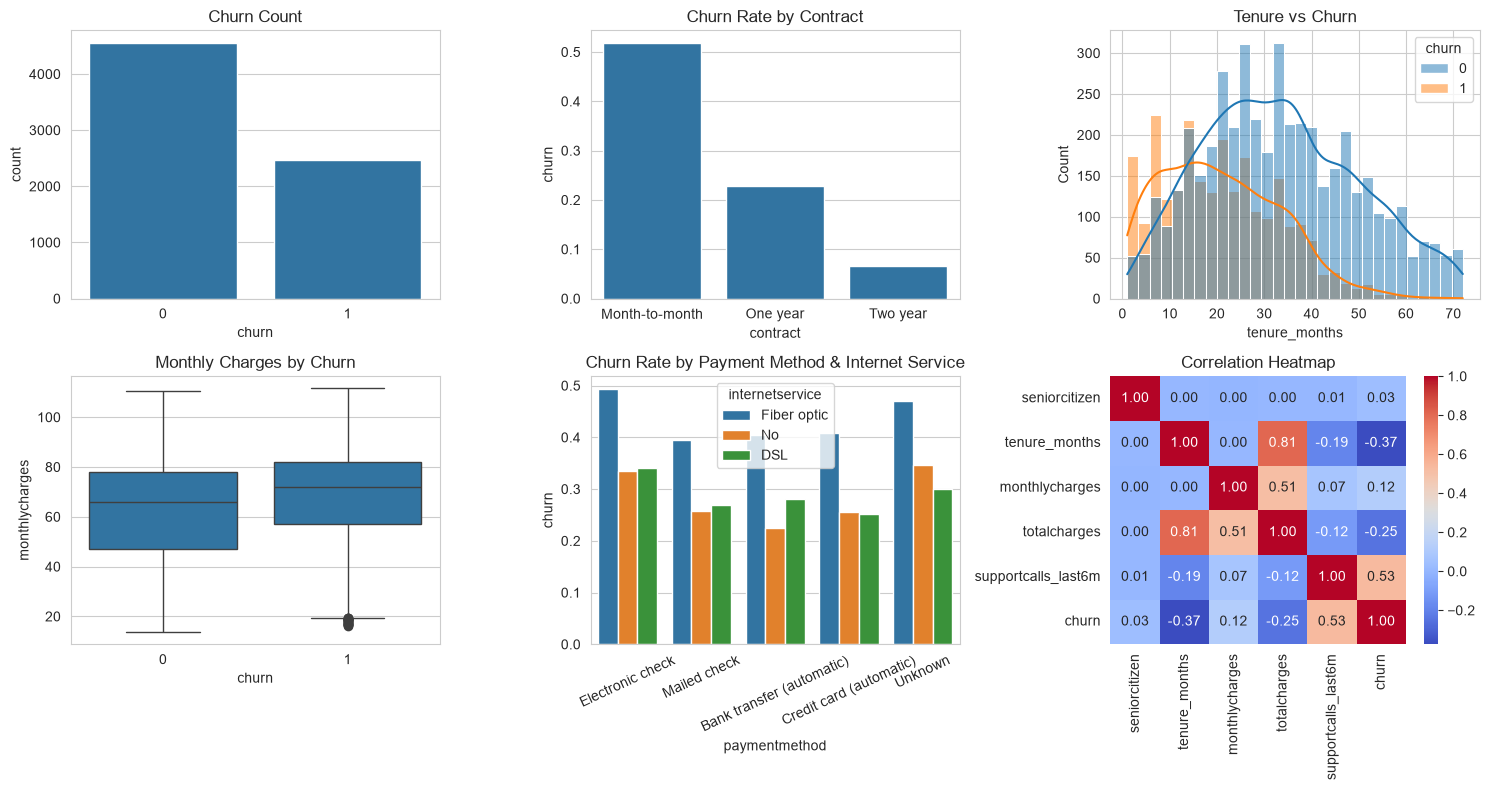

In [364]:
df["churn"]=df["churn"].replace({"Yes":1,"No":0})
df["churn"]=pd.to_numeric(df["churn"])


sns.set_style("whitegrid")
# df = pd.read_csv("your_file.csv")
df["totalcharges"] = pd.to_numeric(df["totalcharges"], errors="coerce")
df["churn"] = df["churn"].astype(int)

fig, ax = plt.subplots(2, 3, figsize=(15, 8))

# 1. Churn distribution
sns.countplot(data=df, x="churn", ax=ax[0, 0])
ax[0, 0].set_title("Churn Count")

# 2. Churn rate by contract
sns.barplot(data=df, x="contract",y="churn", errorbar=None, ax=ax[0, 1])
ax[0, 1].set_title("Churn Rate by Contract")

# 3. Tenure distribution by churn
sns.histplot(data=df, x="tenure_months", hue="churn", kde=True, bins=30, ax=ax[0, 2])
ax[0, 2].set_title("Tenure vs Churn")

# 4. Monthly charges by churn
sns.boxplot(data=df, x="churn", y="monthlycharges", ax=ax[1, 0])
ax[1, 0].set_title("Monthly Charges by Churn")

# 5. Churn rate by internet service and payment method
sns.barplot(data=df, x="paymentmethod", y="churn", hue="internetservice", errorbar=None, ax=ax[1, 1])
ax[1, 1].set_title("Churn Rate by Payment Method & Internet Service")
ax[1, 1].tick_params(axis="x", rotation=25)

# 6. Correlation heatmap
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1, 2])
ax[1, 2].set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()

In [365]:
df["paymentmethod"].value_counts()

paymentmethod
Electronic check             2398
Mailed check                 1551
Bank transfer (automatic)    1519
Credit card (automatic)      1447
Unknown                       105
Name: count, dtype: int64

In [366]:
df.head()

,customerid,gender,seniorcitizen,partner,dependents,city,tenure_months,phoneservice,multiplelines,internetservice,...,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,supportcalls_last6m,churn
0,CUS-13695,Female,0,Yes,Yes,Delhi,19,Yes,No,Fiber optic,...,No,No,Yes,Month-to-month,Yes,Electronic check,77.810000,1482.31,2,1
1,CUS-15342,Female,0,Yes,Yes,Bengaluru,25,Yes,No,Fiber optic,...,No,No,Yes,Month-to-month,Yes,Mailed check,85.850000,2085.52,7,1
2,CUS-11885,Female,0,No,No,Delhi,17,Yes,No,Fiber optic,...,No,No,No,Month-to-month,No,Mailed check,63.477059,1079.11,3,1
3,CUS-12043,Female,0,Yes,No,Hyderabad,56,Yes,No,Fiber optic,...,No,No,Yes,One year,Yes,Bank transfer (automatic),78.050000,4280.76,1,0
4,CUS-12560,Female,0,No,No,Delhi,62,Yes,Yes,No,...,No internet service,No internet service,No internet service,Two year,Yes,Mailed check,31.210000,1931.03,1,0


In [367]:
df.drop("customerid",axis="columns",inplace=True)

In [368]:
df.drop("supportcalls_last6m",axis="columns",inplace=True)

In [369]:
df['totalcharges'].values

array([1482.31, 2085.52, 1079.11, ..., 2900.71, 2041.76, 1822.42],
      shape=(7020,))

In [370]:
df['monthlycharges'].values

array([77.81      , 85.85      , 63.47705882, ..., 55.39      ,
       49.8       , 48.15      ], shape=(7020,))

In [371]:
df["totalcharges"]=pd.to_numeric(df["totalcharges"])

In [372]:
df.shape

(7020, 21)

Text(0.5, 1.0, 'red=churn  green=no churn')

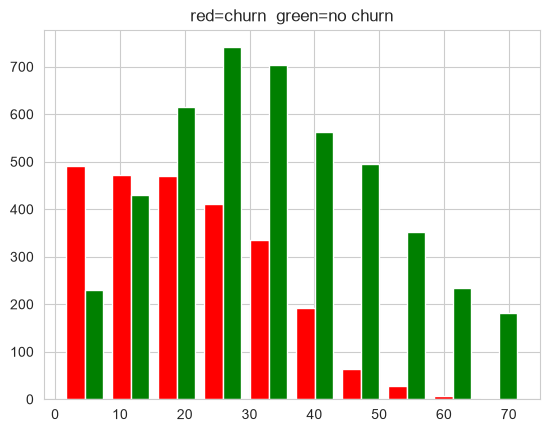

In [373]:
tenure_churn_no=df.loc[df["churn"]==0].tenure_months
tenure_churn_yes=df.loc[df["churn"]==1].tenure_months
plt.hist([tenure_churn_yes, tenure_churn_no],color=["red","green"])
plt.title("red=churn  green=no churn")

In [374]:
df.columns

Index(['gender', 'seniorcitizen', 'partner', 'dependents', 'city',
       'tenure_months', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='str')

Text(0.5, 1.0, 'red=churn  green=no churn')

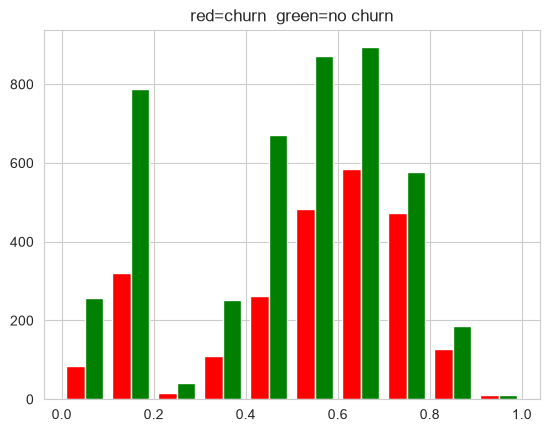

In [406]:
tenure_churn_no=df.loc[df["churn"]==0].monthlycharges
tenure_churn_yes=df.loc[df["churn"]==1].monthlycharges
plt.hist([tenure_churn_yes, tenure_churn_no],color=["red","green"])
plt.title("red=churn  green=no churn")

In [407]:
# def unique_col_values(df):
#     for column in df:
#         if df[column].dtype=="object":
#             print(f"{column}:{df[column].unique()}")

In [408]:
for column in df:
    print(f"{column}:{df[column].unique()}")

gender:[1 0]
seniorcitizen:[0 1]
partner:[1 0]
dependents:[1 0]
city:[1 2 3 4 5 6 7 8]
tenure_months:[0.25352113 0.33802817 0.22535211 0.77464789 0.85915493 0.30985915
 0.26760563 0.5915493  0.07042254 0.53521127 0.6056338  0.35211268
 0.32394366 0.92957746 0.4084507  0.81690141 0.71830986 0.09859155
 0.67605634 0.18309859 0.61971831 0.56338028 0.28169014 0.12676056
 0.43661972 0.8028169  0.36619718 0.38028169 0.52112676 0.98591549
 0.02816901 0.04225352 0.49295775 0.69014085 0.45070423 0.46478873
 0.70422535 0.64788732 0.42253521 0.3943662  0.05633803 0.63380282
 0.50704225 0.         0.57746479 0.1971831  0.74647887 0.23943662
 0.88732394 0.84507042 0.29577465 0.15492958 0.54929577 0.47887324
 0.11267606 0.14084507 0.21126761 0.08450704 0.73239437 0.16901408
 0.94366197 0.66197183 0.83098592 0.90140845 0.87323944 0.95774648
 0.76056338 0.91549296 0.97183099 1.         0.78873239 0.01408451]
phoneservice:[1 0]
multiplelines:[0 1]
internetservice:[1 2 3]
onlinesecurity:[0 1]
onlineback

In [409]:
df.replace("No internet service","No",inplace=True)
df.replace("No phone service","No",inplace=True)

,gender,seniorcitizen,partner,dependents,city,tenure_months,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,1,0,1,1,1,0.253521,1,0,1,0,...,0,0,0,1,1,1,1,0.655190,0.211657,1
1,1,0,1,1,2,0.338028,1,0,1,0,...,1,0,0,1,1,1,2,0.737331,0.299005,1
2,1,0,0,0,1,0.225352,1,0,1,0,...,0,0,0,0,1,0,2,0.508756,0.153272,1
3,1,0,1,0,3,0.774648,1,0,1,0,...,0,0,0,1,2,1,3,0.657642,0.616887,0
4,1,0,0,0,1,0.859155,1,1,2,0,...,0,0,0,0,3,1,2,0.179097,0.276634,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7015,1,0,0,0,4,0.070423,1,0,1,1,...,1,0,1,0,2,1,2,0.751430,0.074456,0
7016,1,0,1,0,3,0.788732,1,1,3,0,...,1,0,1,0,2,0,2,0.556804,0.548377,0
7017,1,0,1,0,6,0.718310,1,0,3,0,...,0,0,1,0,2,1,3,0.426134,0.417049,0
7018,0,1,1,0,3,0.577465,1,1,3,0,...,0,0,0,0,2,0,1,0.369023,0.292669,0


In [410]:
for column in df:
    print(f"{column}:{df[column].unique()}")

gender:[1 0]
seniorcitizen:[0 1]
partner:[1 0]
dependents:[1 0]
city:[1 2 3 4 5 6 7 8]
tenure_months:[0.25352113 0.33802817 0.22535211 0.77464789 0.85915493 0.30985915
 0.26760563 0.5915493  0.07042254 0.53521127 0.6056338  0.35211268
 0.32394366 0.92957746 0.4084507  0.81690141 0.71830986 0.09859155
 0.67605634 0.18309859 0.61971831 0.56338028 0.28169014 0.12676056
 0.43661972 0.8028169  0.36619718 0.38028169 0.52112676 0.98591549
 0.02816901 0.04225352 0.49295775 0.69014085 0.45070423 0.46478873
 0.70422535 0.64788732 0.42253521 0.3943662  0.05633803 0.63380282
 0.50704225 0.         0.57746479 0.1971831  0.74647887 0.23943662
 0.88732394 0.84507042 0.29577465 0.15492958 0.54929577 0.47887324
 0.11267606 0.14084507 0.21126761 0.08450704 0.73239437 0.16901408
 0.94366197 0.66197183 0.83098592 0.90140845 0.87323944 0.95774648
 0.76056338 0.91549296 0.97183099 1.         0.78873239 0.01408451]
phoneservice:[1 0]
multiplelines:[0 1]
internetservice:[1 2 3]
onlinesecurity:[0 1]
onlineback

In [380]:
df[["partner","dependents","phoneservice","multiplelines","onlinesecurity","onlinebackup","deviceprotection","techsupport","streamingtv"
    ,"streamingmovies","paperlessbilling"]]=df[["partner","dependents","phoneservice","multiplelines","onlinesecurity","onlinebackup","deviceprotection","techsupport","streamingtv"
    ,"streamingmovies","paperlessbilling"]].replace({"Yes":1,"No":0})

In [381]:
for col in df:
    print(f"{col}:{df[col].unique()}")

gender:<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
seniorcitizen:[0 1]
partner:[1 0]
dependents:[1 0]
city:<ArrowStringArray>
[    'Delhi', 'Bengaluru', 'Hyderabad',      'Pune',   'Kolkata',    'Mumbai',
   'Chennai', 'Ahmedabad']
Length: 8, dtype: str
tenure_months:[19 25 17 56 62 23 20 43  6 39 44 26 24 67 30 59 52  8 49 14 45 41 21 10
 32 58 27 28 38 71  3  4 36 50 33 34 51 47 31 29  5 46 37  1 42 15 54 18
 64 61 22 12 40 35  9 11 16  7 53 13 68 48 60 65 63 69 55 66 70 72 57  2]
phoneservice:[1 0]
multiplelines:[0 1]
internetservice:<ArrowStringArray>
['Fiber optic', 'No', 'DSL']
Length: 3, dtype: str
onlinesecurity:[0 1]
onlinebackup:[0 1]
deviceprotection:[0 1]
techsupport:[0 1]
streamingtv:[0 1]
streamingmovies:[1 0]
contract:<ArrowStringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str
paperlessbilling:[1 0]
paymentmethod:<ArrowStringArray>
[         'Electronic check',              'Mailed check',
 'Bank transfer (automatic)',   'Credit ca

In [382]:
df["gender"]=df["gender"].replace({"Female":1,"Male":0})

df["city"]=df["city"].replace({'Delhi':1, 'Bengaluru':2, 'Hyderabad':3,      'Pune':4,   'Kolkata':5,    'Mumbai':6,
   'Chennai':7, 'Ahmedabad':8})

df["internetservice"]=df["internetservice"].replace({'Fiber optic':1, 'No':2, 'DSL':3})

df["contract"]=df["contract"].replace({'Month-to-month':1, 'One year':2, 'Two year':3})

df["paymentmethod"]=df["paymentmethod"].replace({'Electronic check':1,'Mailed check':2,
 'Bank transfer (automatic)':3,   'Credit card (automatic)':4,
                   'Unknown':5})

In [383]:
df

,gender,seniorcitizen,partner,dependents,city,tenure_months,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,1,0,1,1,1,19,1,0,1,0,...,0,0,0,1,1,1,1,77.810000,1482.31,1
1,1,0,1,1,2,25,1,0,1,0,...,1,0,0,1,1,1,2,85.850000,2085.52,1
2,1,0,0,0,1,17,1,0,1,0,...,0,0,0,0,1,0,2,63.477059,1079.11,1
3,1,0,1,0,3,56,1,0,1,0,...,0,0,0,1,2,1,3,78.050000,4280.76,0
4,1,0,0,0,1,62,1,1,2,0,...,0,0,0,0,3,1,2,31.210000,1931.03,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7015,1,0,0,0,4,6,1,0,1,1,...,1,0,1,0,2,1,2,87.230000,534.82,0
7016,1,0,1,0,3,57,1,1,3,0,...,1,0,1,0,2,0,2,68.180000,3807.64,0
7017,1,0,1,0,6,52,1,0,3,0,...,0,0,1,0,2,1,3,55.390000,2900.71,0
7018,0,1,1,0,3,42,1,1,3,0,...,0,0,0,0,2,0,1,49.800000,2041.76,0


In [384]:
df.dtypes

gender               object
seniorcitizen         int64
partner              object
dependents           object
city                 object
tenure_months         int64
phoneservice         object
multiplelines        object
internetservice      object
onlinesecurity       object
onlinebackup         object
deviceprotection     object
techsupport          object
streamingtv          object
streamingmovies      object
contract             object
paperlessbilling     object
paymentmethod        object
monthlycharges      float64
totalcharges        float64
churn                 int64
dtype: object

In [385]:
df = df.apply(pd.to_numeric, errors="raise")

In [386]:
df.dtypes

gender                int64
seniorcitizen         int64
partner               int64
dependents            int64
city                  int64
tenure_months         int64
phoneservice          int64
multiplelines         int64
internetservice       int64
onlinesecurity        int64
onlinebackup          int64
deviceprotection      int64
techsupport           int64
streamingtv           int64
streamingmovies       int64
contract              int64
paperlessbilling      int64
paymentmethod         int64
monthlycharges      float64
totalcharges        float64
churn                 int64
dtype: object

In [387]:
df.shape

(7020, 21)

In [388]:
from sklearn.preprocessing import MinMaxScaler

columns_to_scale = ["tenure_months", "monthlycharges", "totalcharges"]

scaler = MinMaxScaler()

df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])

In [389]:
df.head()

,gender,seniorcitizen,partner,dependents,city,tenure_months,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,1,0,1,1,1,0.253521,1,0,1,0,...,0,0,0,1,1,1,1,0.655190,0.211657,1
1,1,0,1,1,2,0.338028,1,0,1,0,...,1,0,0,1,1,1,2,0.737331,0.299005,1
2,1,0,0,0,1,0.225352,1,0,1,0,...,0,0,0,0,1,0,2,0.508756,0.153272,1
3,1,0,1,0,3,0.774648,1,0,1,0,...,0,0,0,1,2,1,3,0.657642,0.616887,0
4,1,0,0,0,1,0.859155,1,1,2,0,...,0,0,0,0,3,1,2,0.179097,0.276634,0


In [390]:
x=df.drop("churn",axis="columns")
y=df["churn"]

In [391]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=5)

In [392]:
x_train.shape

(5616, 20)

In [393]:
x_test.shape

(1404, 20)

In [394]:
x_train.head()
# x_test.head()
y_train.head()
# y_test.head()

1323    0
2675    1
4970    0
5432    0
1502    1
Name: churn, dtype: int64

In [395]:
import tensorflow as tf
from tensorflow import keras

model = keras.Sequential([
    keras.layers.Dense(20, input_shape=(x_train.shape[1],), activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),])

model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

model.fit(x_train,y_train,epochs=100)

C:\Users\MOHAMMED RIZWAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6457 - loss: 0.6307
Epoch 2/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6920 - loss: 0.5563
Epoch 3/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7121 - loss: 0.5317
Epoch 4/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7229 - loss: 0.5207
Epoch 5/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7292 - loss: 0.5136
Epoch 6/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7327 - loss: 0.5103
Epoch 7/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7354 - loss: 0.5065
Epoch 8/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7345 - loss: 0.5049
Epoch 9/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7425 - loss: 0.5044
Epoch 10/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7402 - loss: 0.5023
Epoch 11/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7436 - loss: 0.5005
Epoch 12/100
176/176 ━━━━━━━━━━━━━━━━━━━━

In [396]:
model.evaluate(x_test,y_test)

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7236 - loss: 0.5274


[0.5274125933647156, 0.7236467003822327]

In [397]:
yp=model.predict(x_test)
yp

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[0.5270667 ],
       [0.14465408],
       [0.01513784],
       ...,
       [0.60497594],
       [0.4399075 ],
       [0.16602363]], shape=(1404, 1), dtype=float32)

In [398]:
y_test[:5]

4380    1
2446    0
6580    0
64      0
6550    0
Name: churn, dtype: int64

In [399]:
y_pred= []
for element in yp:
    if element>0.5:
        y_pred.append(1)
    else:
        y_pred.append(0)

In [400]:
y_pred[:10]

[1, 0, 0, 0, 0, 1, 0, 1, 1, 0]

In [401]:

from sklearn.metrics import confusion_matrix,classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.78      0.79      0.79       911
           1       0.61      0.59      0.60       493

    accuracy                           0.72      1404
   macro avg       0.70      0.69      0.69      1404
weighted avg       0.72      0.72      0.72      1404



Text(51.68782552083333, 0.5, 'Truth')

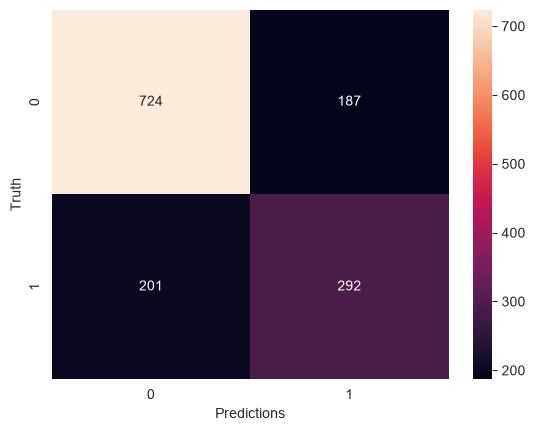

In [402]:
cm=tf.math.confusion_matrix(labels=y_test,predictions=y_pred)

sns.heatmap(cm,annot=True,fmt="d")
plt.xlabel("Predictions")
plt.ylabel("Truth")

In [418]:
predicted_data = x_test.copy()
predicted_data["actual_churn"] = y_test
predicted_data["predicted_churn"] = [int(p[0] >= 0.5) for p in yp]
predicted_data["churn_probability"] = yp.ravel()

predicted_data.tail(10)

,gender,seniorcitizen,partner,dependents,city,tenure_months,phoneservice,multiplelines,internetservice,onlinesecurity,...,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,actual_churn,predicted_churn,churn_probability
5844,1,0,1,1,8,0.154930,1,0,2,0,...,0,0,2,0,1,0.072844,0.032351,0,0,0.419268
3950,1,0,0,0,2,0.352113,1,0,2,0,...,0,0,1,0,4,0.109318,0.088186,1,0,0.402867
4675,0,1,1,1,7,0.450704,1,0,2,0,...,0,0,1,1,1,0.094197,0.106441,0,1,0.577126
3564,0,0,1,0,3,0.521127,1,0,3,1,...,0,1,1,1,2,0.500817,0.331733,0,0,0.206236
1293,0,0,1,0,2,0.450704,1,1,2,0,...,0,0,2,1,3,0.144565,0.128280,0,0,0.096054
6131,0,0,0,0,6,0.690141,1,0,3,0,...,0,0,1,0,2,0.318655,0.329829,0,0,0.187623
1428,1,0,0,0,8,0.000000,1,0,1,0,...,0,0,1,0,2,0.565080,0.006855,1,1,0.866049
101,1,0,0,0,2,0.154930,1,0,3,0,...,0,0,1,0,2,0.355640,0.081485,0,1,0.604976
2864,1,0,0,0,2,0.450704,1,0,1,0,...,1,0,1,0,2,0.622906,0.352831,0,0,0.439907
392,0,0,0,1,2,0.169014,1,0,1,1,...,0,1,3,1,1,0.638435,0.144172,1,0,0.166024


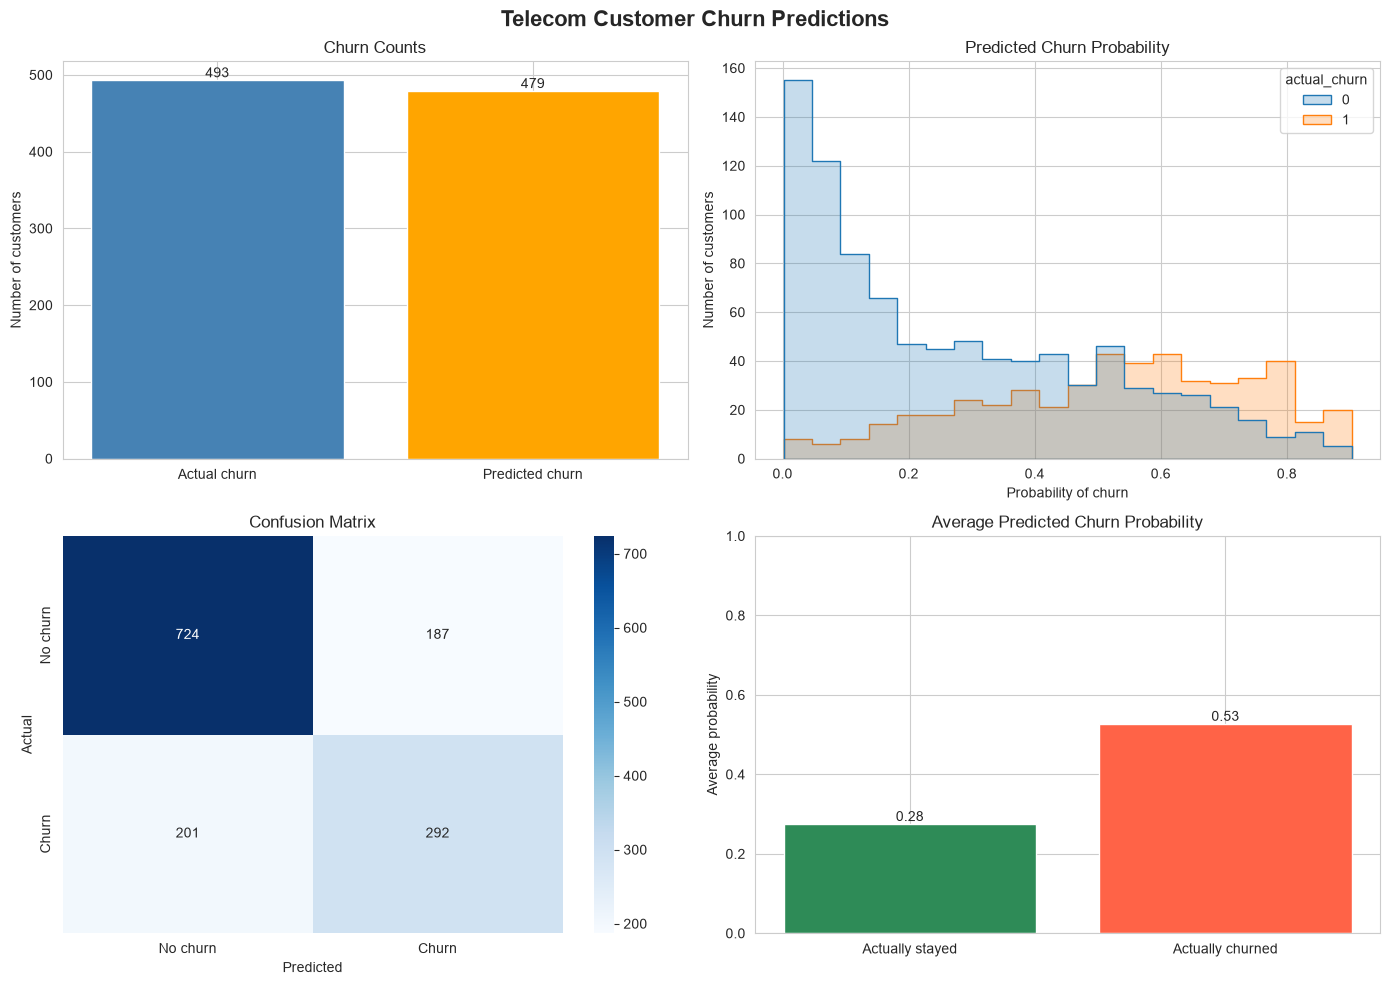

In [413]:
# from sklearn.metrics import confusion_matrix

# Make a 2x2 chart dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Telecom Customer Churn Predictions", fontsize=16, fontweight="bold")

# 1. Actual vs predicted churn counts
counts = predicted_data[["actual_churn", "predicted_churn"]].sum()
axes[0, 0].bar(["Actual churn", "Predicted churn"],counts.values,color=["steelblue", "orange"])
axes[0, 0].set_title("Churn Counts")
axes[0, 0].set_ylabel("Number of customers")
axes[0, 0].bar_label(axes[0, 0].containers[0])

# 2. Predicted churn probability distribution
sns.histplot(
    data=predicted_data,
    x="churn_probability",
    hue="actual_churn",
    bins=20,
    element="step",
    stat="count",
    common_norm=False,
    ax=axes[0, 1])
axes[0, 1].set_title("Predicted Churn Probability")
axes[0, 1].set_xlabel("Probability of churn")
axes[0, 1].set_ylabel("Number of customers")

# 3. Confusion matrix
cm = confusion_matrix(
    predicted_data["actual_churn"],
    predicted_data["predicted_churn"])
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No churn", "Churn"],
    yticklabels=["No churn", "Churn"],
    ax=axes[1, 0])
axes[1, 0].set_title("Confusion Matrix")
axes[1, 0].set_xlabel("Predicted")
axes[1, 0].set_ylabel("Actual")

# 4. Average churn probability by actual churn
avg_probability = predicted_data.groupby("actual_churn")["churn_probability"].mean()
axes[1, 1].bar(
    ["Actually stayed", "Actually churned"],
    avg_probability.values,
    color=["seagreen", "tomato"])
axes[1, 1].set_title("Average Predicted Churn Probability")
axes[1, 1].set_ylabel("Average probability")
axes[1, 1].set_ylim(0, 1)
axes[1, 1].bar_label(
    axes[1, 1].containers[0],
    fmt="%.2f")

plt.tight_layout()
plt.show()

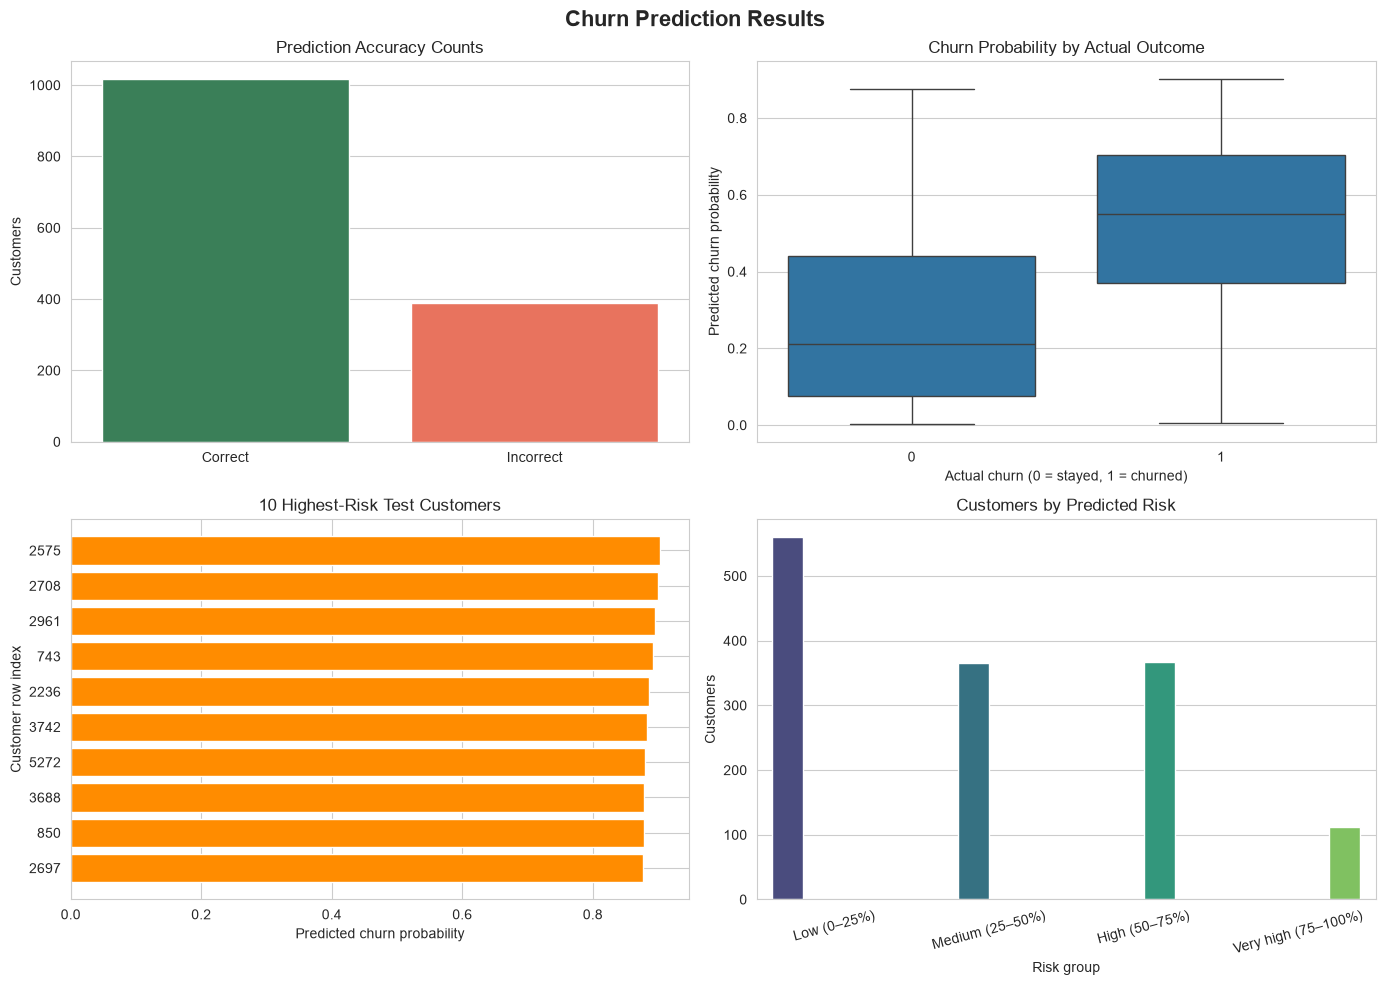

In [417]:

# Label each prediction as correct or incorrect
chart_data = predicted_data.copy()
chart_data["result"] = (
    chart_data["actual_churn"] == chart_data["predicted_churn"]).map({True: "Correct", False: "Incorrect"})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Churn Prediction Results", fontsize=16, fontweight="bold")

# 1. Correct vs incorrect predictions
sns.countplot(data=chart_data, x="result", hue="result",
              palette={"Correct": "seagreen", "Incorrect": "tomato"},
              legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Prediction Accuracy Counts")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Customers")

# 2. Probability distribution by actual outcome
sns.boxplot(data=chart_data, x="actual_churn", y="churn_probability", ax=axes[0, 1])
axes[0, 1].set_title("Churn Probability by Actual Outcome")
axes[0, 1].set_xlabel("Actual churn (0 = stayed, 1 = churned)")
axes[0, 1].set_ylabel("Predicted churn probability")

# 3. Ten customers with the highest predicted churn probability
top10 = chart_data.nlargest(10, "churn_probability").sort_values("churn_probability")
axes[1, 0].barh(top10.index.astype(str), top10["churn_probability"], color="darkorange")
axes[1, 0].set_title("10 Highest-Risk Test Customers")
axes[1, 0].set_xlabel("Predicted churn probability")
axes[1, 0].set_ylabel("Customer row index")

# 4. Prediction counts by probability range
chart_data["risk_group"] = pd.cut(
    chart_data["churn_probability"],
    bins=[0, 0.25, 0.50, 0.75, 1.0],
    labels=["Low (0–25%)", "Medium (25–50%)", "High (50–75%)", "Very high (75–100%)"],
    include_lowest=True)
sns.countplot(data=chart_data, x="risk_group", hue="risk_group",
              palette="viridis", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Customers by Predicted Risk")
axes[1, 1].set_xlabel("Risk group")
axes[1, 1].set_ylabel("Customers")
axes[1, 1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

In [419]:
predicted_data.to_csv("telcome_churn_predict.csv",index=True)